🚗CAR PRICE PREDICTION💵


DATASET SOURCE:

https://drive.google.com/file/d/1FHmYNLs9v0Enc-UExEMpitOFGsWvB2dP/view?usp=drive_link

DATASET LOADING

In [30]:
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

df=pd.read_csv("CarPrice_Assignment.csv")

DATA PREPROCESSING

In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    str    
 3   fueltype          205 non-null    str    
 4   aspiration        205 non-null    str    
 5   doornumber        205 non-null    str    
 6   carbody           205 non-null    str    
 7   drivewheel        205 non-null    str    
 8   enginelocation    205 non-null    str    
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    str    
 15  cylindernumber    205 non-null    str    
 16  enginesize        205 non-null    int64  
 17  fuelsyst

Dataset contain float,integer and object variables


In [32]:
df.shape

(205, 26)

Dataset contain 205 rows and 26 columns

In [33]:
df.isnull().sum()

car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

No Null values identified.

In [34]:
df.duplicated().sum()

np.int64(0)

No Duplicate rows have been identified

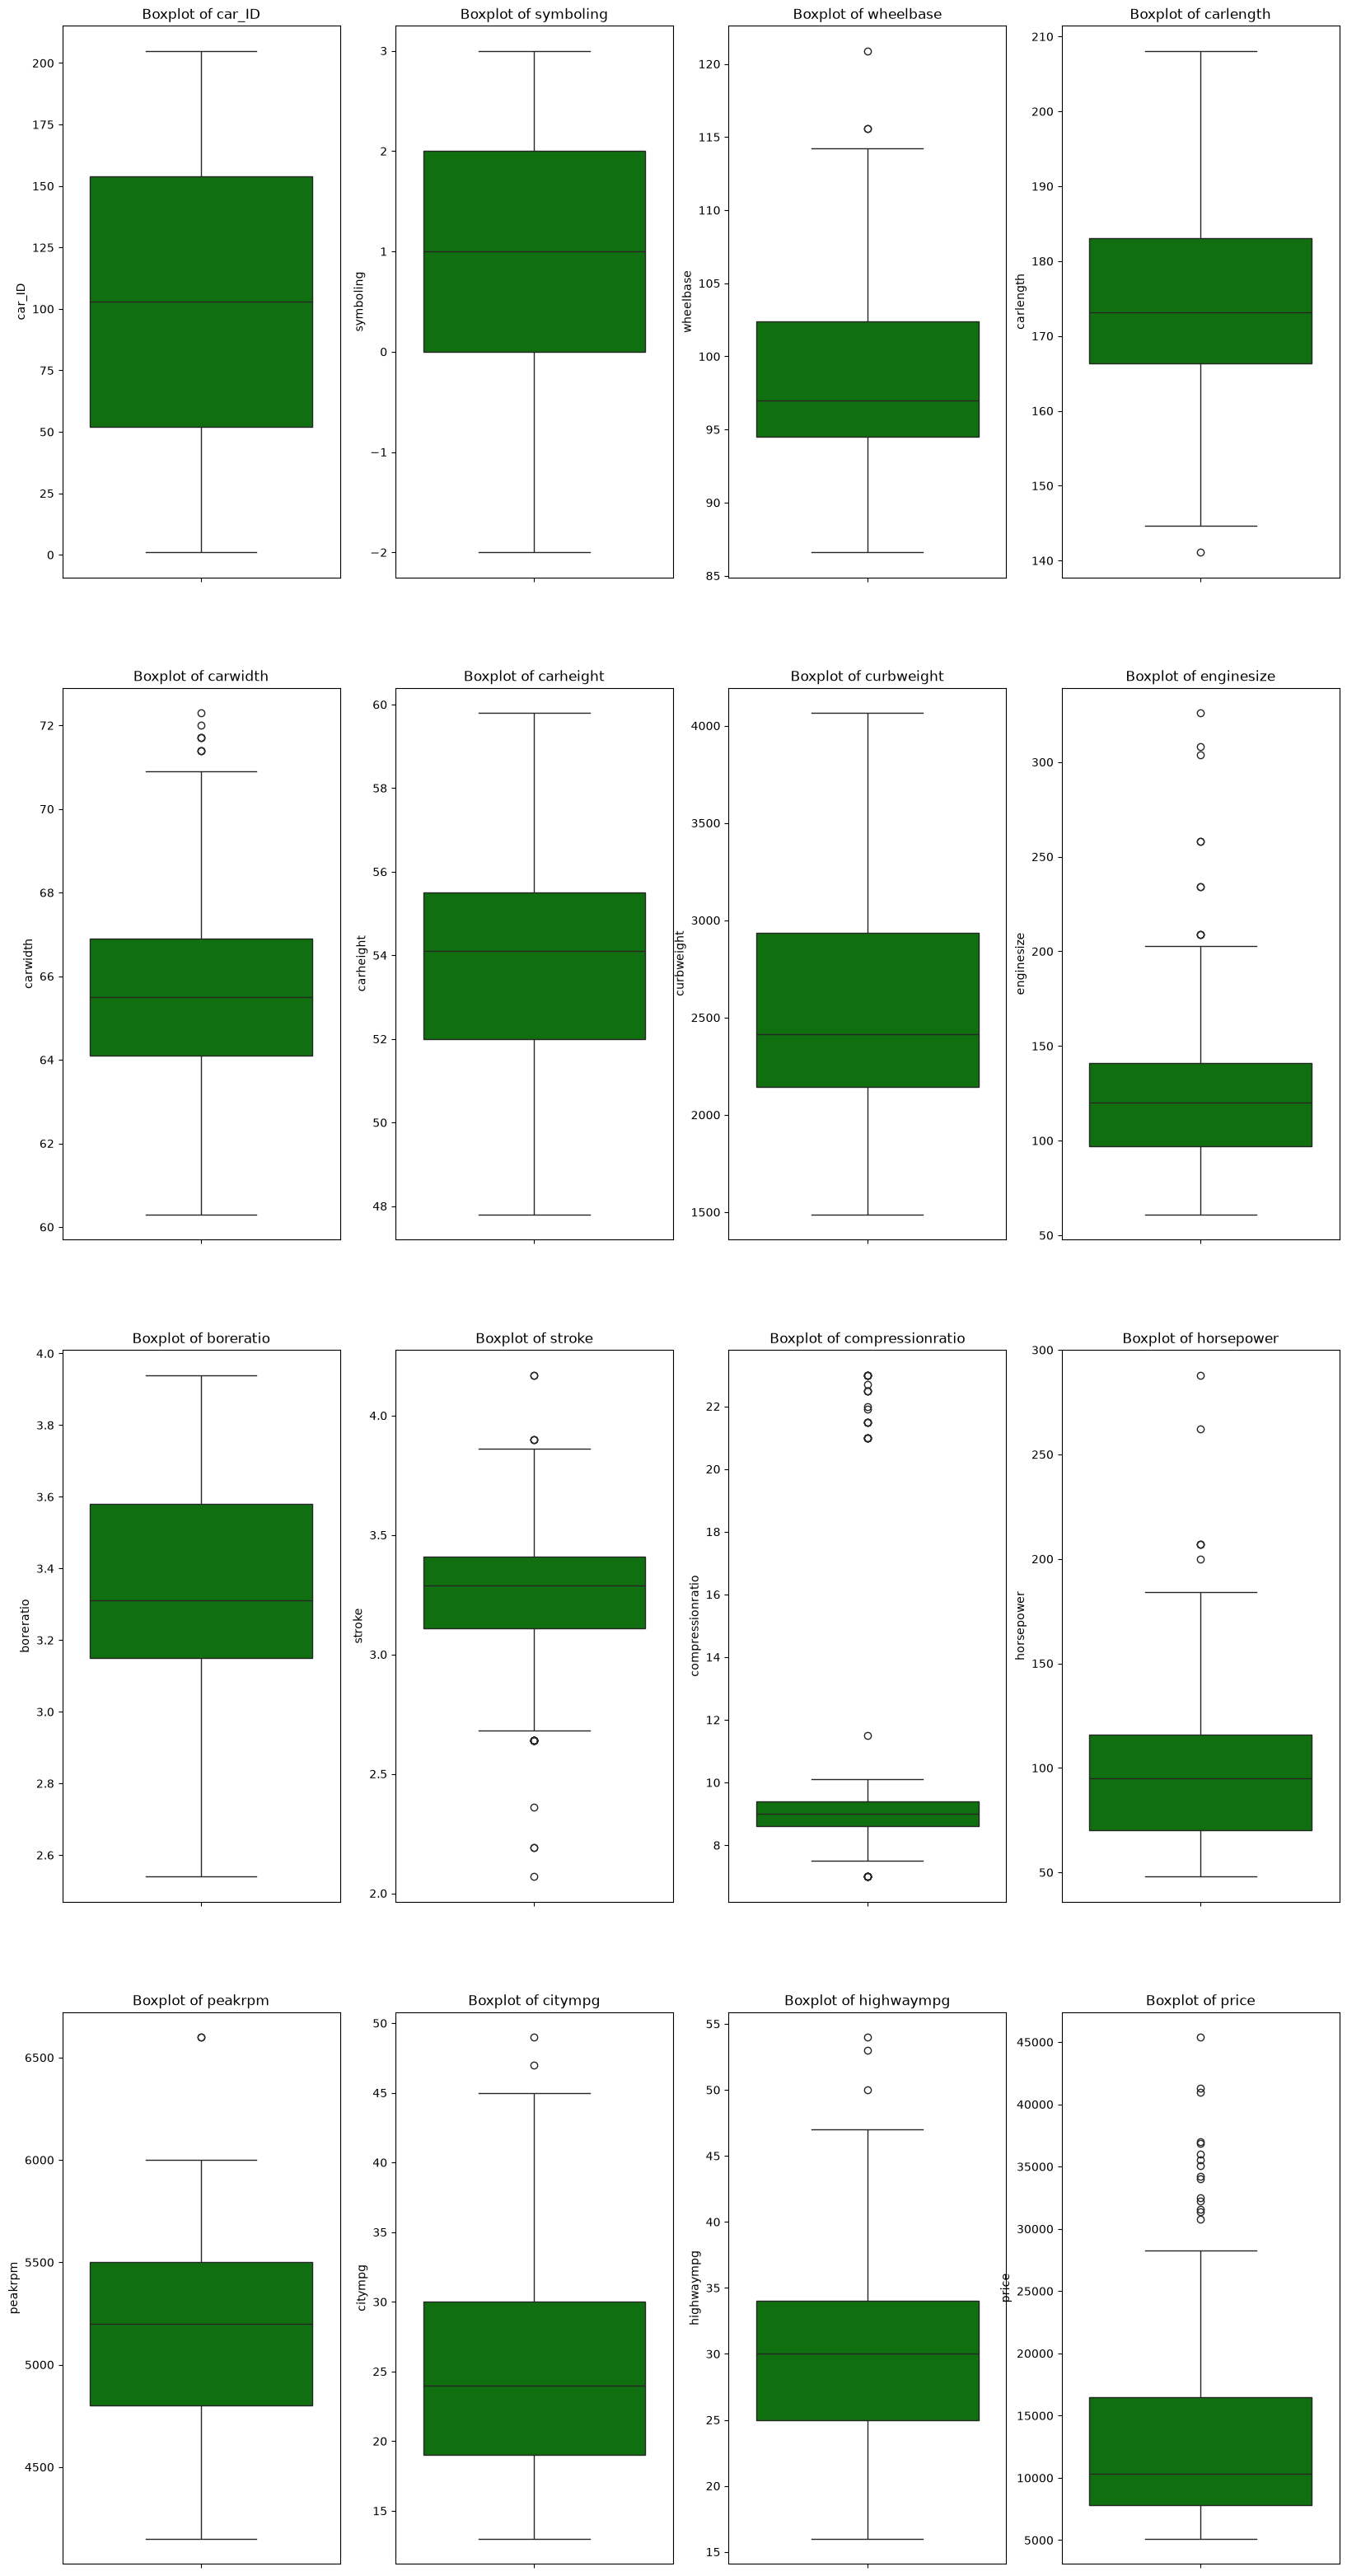

In [35]:
from numpy._core import numeric
import matplotlib.pyplot as plt
import seaborn as sns
num_cols=df.select_dtypes(include=['int64','float64']).columns
fig,ax=plt.subplots(4,4,figsize=(20,40))
count=0
for i in range(4):
  for j in range(4):
    if count < len(num_cols):
     sns.boxplot(data=df,y=df[num_cols[count]],color='green',ax=ax[i][j])
     ax[i][j].set_title("Boxplot of "+num_cols[count])
     count+=1

plt.show()


In [7]:
df['compressionratio'].sort_values(ascending=False)

192    23.0
184    23.0
182    23.0
187    23.0
203    23.0
       ... 
117     7.0
83      7.0
124     7.0
84      7.0
82      7.0
Name: compressionratio, Length: 205, dtype: float64

For compression-ratio, values such as:

7.0 - 10.0 (common)
21.0 - 23.0 (diesel engines)

As compression ratio have high values as 23 in the datsetSo no need of removing outliers.

In [8]:
df['enginesize'].sort_values(ascending=False)

49    326
73    308
74    304
48    258
47    258
     ... 
32     79
57     70
56     70
55     70
18     61
Name: enginesize, Length: 205, dtype: int64

Some sports car engine size vary upto 300+.As this is also a real value,so removing outliers not required

In [9]:
df['horsepower'].sort_values(ascending=False)

129    288
49     262
126    207
128    207
127    207
      ... 
159     56
90      55
182     52
184     52
18      48
Name: horsepower, Length: 205, dtype: int64

Horse power high values are also normal.Can avoid removing outliers

In [10]:
df['stroke'].sort_values(ascending=False)

47     4.17
48     4.17
29     3.90
130    3.90
131    3.90
       ... 
141    2.64
138    2.36
113    2.19
111    2.19
134    2.07
Name: stroke, Length: 205, dtype: float64

values like 2.07, 3.03, 4.17 are present and correspond to real vehicles, they are natural variations, not errors.

In [11]:
df['highwaympg'].sort_values(ascending=False)

30     54
18     53
90     50
159    47
160    47
       ..
72     18
71     18
49     17
73     16
74     16
Name: highwaympg, Length: 205, dtype: int64

highwaympg values are typically:

Minimum: ~16 mpg
Maximum: ~54 mpg

cannot be identify as outliers

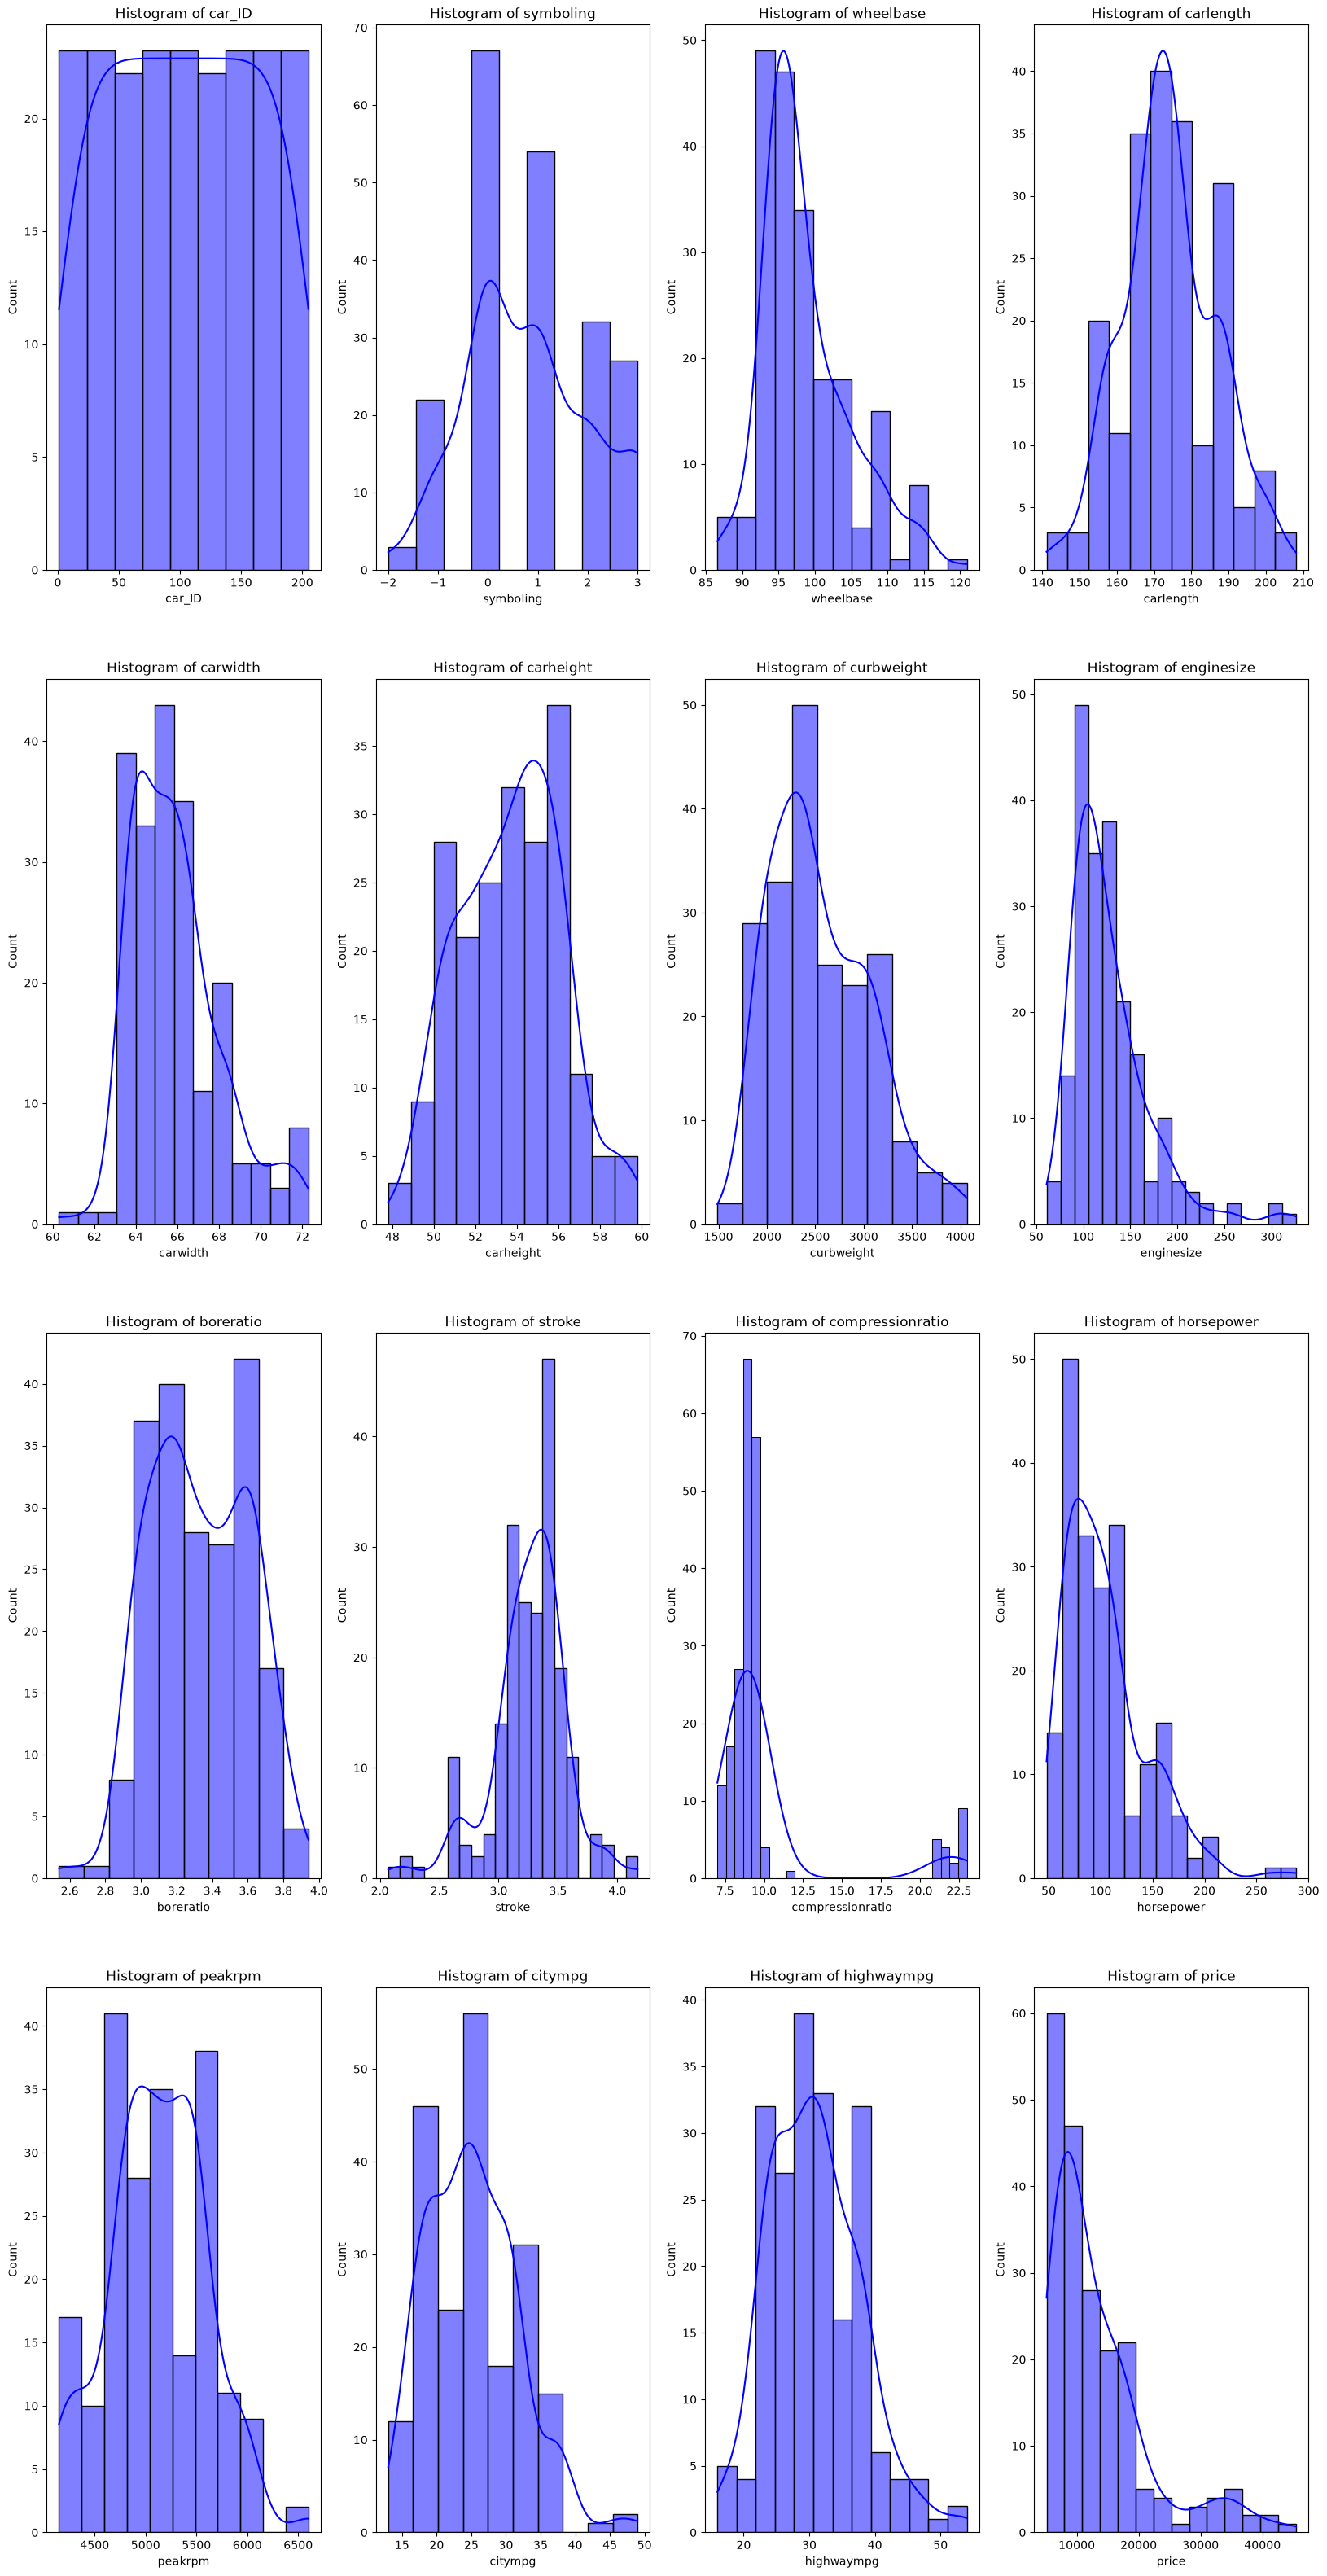

In [36]:
fig,ax=plt.subplots(4,4,figsize=(20,40))
count=0
for i in range(4):
     for j in range(4):
         if count <len(num_cols):
             sns.histplot(data=df,x=df[num_cols[count]],color='blue',kde=True,ax=ax[i][j])
             ax[i][j].set_title("Histogram of "+num_cols[count])
             count+=1
plt.show()             

Some columna are =vely skewed

In [38]:
skew_cols=df[num_cols].skew().sort_values(ascending=False)
print(skew_cols[(skew_cols > 1) | (skew_cols < -1)])

compressionratio    2.610862
enginesize          1.947655
price               1.777678
horsepower          1.405310
wheelbase           1.050214
dtype: float64


price is the target variable.So except price,reducing skewness by log transformation

In [39]:
import numpy as np
skews=["compressionratio","horsepower","enginesize","wheelbase"]
for i in range(4):
    df[skews[i]] = np.log1p(df[skews[i]])
df[num_cols].skew()    

car_ID              0.000000
symboling           0.211072
wheelbase           0.885024
carlength           0.155954
carwidth            0.904003
carheight           0.063123
curbweight          0.681398
enginesize          0.864706
boreratio           0.020156
stroke             -0.689705
compressionratio    2.379056
horsepower          0.489938
peakrpm             0.075159
citympg             0.663704
highwaympg          0.539997
price               1.777678
dtype: float64

EXPLORATORY DATA ANALYSIS

In [40]:
df.describe()

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,4.600984,174.049268,65.907805,53.724878,2555.565854,4.808683,3.329756,3.255415,2.368801,4.594039,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,0.058782,12.337289,2.145204,2.443522,520.680204,0.280828,0.270844,0.313597,0.261981,0.341525,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,4.472781,141.100000,60.300000,47.800000,1488.000000,4.127134,2.540000,2.070000,2.079442,3.891820,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,4.559126,166.300000,64.100000,52.000000,2145.000000,4.584967,3.150000,3.110000,2.261763,4.262680,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,4.584967,173.200000,65.500000,54.100000,2414.000000,4.795791,3.310000,3.290000,2.302585,4.564348,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,4.638605,183.100000,66.900000,55.500000,2935.000000,4.955827,3.580000,3.410000,2.341806,4.762174,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,4.803201,208.100000,72.300000,59.800000,4066.000000,5.789960,3.940000,4.170000,3.178054,5.666427,6600.000000,49.000000,54.000000,45400.000000


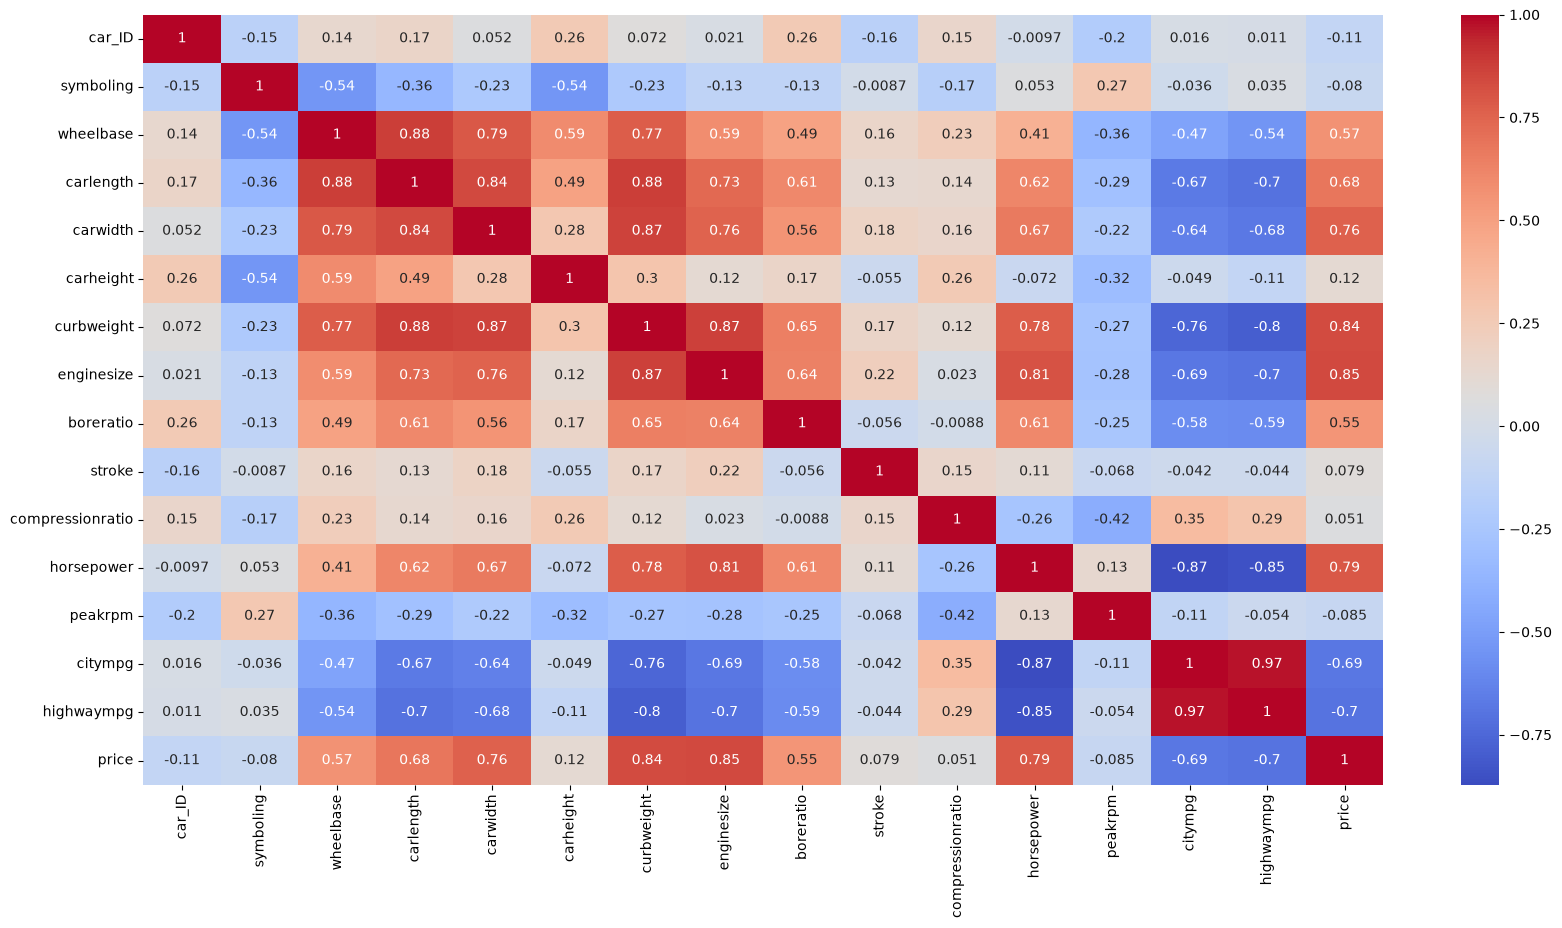

In [41]:
plt.figure(figsize=(20,10))
sns.heatmap(df[num_cols].corr(),annot=True,cmap='coolwarm')
plt.show()

OBSERVATION:

Price Variable have +ve correlation withbreratio,enginesize,curbweight,carwidth,carlength,wheelbase

Price varivale have -ve correlation with highwaympg and citympg

price variable have no correlation with carID,symboling,compressionratio and stroke

FEATURE ENGINEERING

In [42]:
from sklearn.preprocessing import LabelEncoder
Le=LabelEncoder()
cat_cols = df.select_dtypes(include=['object']).columns
for i in range(len(cat_cols)):
    df[cat_cols[i]]=Le.fit_transform(df[cat_cols[i]])
    
    
    


SPLITTING DATASET INTO DEPENDENT AND INDEPENDENT VARIABLES

In [121]:
X=df.drop(columns=['price'])
y=df['price']

FEATURE SELECTION

In [85]:
from sklearn.feature_selection import SelectKBest,f_regression
selector=SelectKBest(score_func=f_regression)
selector.fit(X,y)

SelectKBest(score_func=<function f_regression at 0x000002A37F2138A0>)

In [86]:
feature_scores=pd.DataFrame({'Feature': X.columns, 'Score': selector.scores_})
feature_scores.sort_values(by='Score',ascending=False)

,Feature,Score
16,enginesize,511.324786
13,curbweight,468.594431
21,horsepower,334.201356
11,carwidth,276.423646
24,highwaympg,192.437464
23,citympg,180.203163
10,carlength,177.420344
7,drivewheel,101.838772
9,wheelbase,97.022611
18,boreratio,89.507470


Best Features have been identified as enginesize,curbweight,horsepower,carwidth,highwaympg,citympg,carlength,drivewheel,wheelbase,boreratio,fuelsystem and enginelocation

Removing all  less score features

In [122]:
X.drop(columns=['symboling','car_ID','enginelocation','cylindernumber','doornumber','enginetype','compressionratio','stroke','carbody','peakrpm'],inplace=True)

TRAIN TEST SPLIT

In [123]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

MODEL IMPLEMENTATION

1.Linear Regression

Linear Regression model works by assuming relationship as a straight line

2.Decion Tree Regressor

It works by repeatedly splitting the dataset into smaller groups based on feature conditions

3.RandomForset Regressor

It combines the predictions of multiple Decision Trees and produces the final prediction by averaging the outputs of all trees.

4.GradientBoosting Regressor

It builds multiple Decision Trees sequentially, where each new tree learns to correct the errors made by the previous trees.

5.Support Vector Regressor

SVR finds a line (or hyperplane) that best fits the data while keeping prediction errors within a specified margin.



In [124]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
models={"Linear Regression":LinearRegression(),
        "Decision Tree":DecisionTreeRegressor(random_state=42),
        "Random Forest":RandomForestRegressor(random_state=42),
        "Gradient Boosting":GradientBoostingRegressor(random_state=42),
        "Support Vector Regression":SVR()}
metrics=pd.DataFrame(columns=["Model","RMSE%","MAE%","R2_Score"])
for name,model in models.items():
    model.fit(X_train,y_train)
    y_pred=model.predict(X_test)
    RMSE=np.sqrt(mean_squared_error(y_test,y_pred))
    RMSE_per=(RMSE/y_test.mean())*100
    MAE=mean_absolute_error(y_test,y_pred)
    MAE_per=(MAE/y_test.mean())*100
    R2=r2_score(y_test,y_pred)             
    metrics = pd.concat(
        [metrics, pd.DataFrame([{
            "Model": name,
            "RMSE%": RMSE_per,
            "MAE%": MAE_per,
            "R2_Score": R2*100
        }])],
        ignore_index=True
    )


MODEL EVALUTAION

In [93]:
metrics.sort_values(by='R2_Score',ascending=False)

,Model,RMSE%,MAE%,R2_Score
2,Random Forest,14.390653,10.129265,95.226259
3,Gradient Boosting,19.901177,13.150417,90.870324
1,Decision Tree,23.690866,15.404997,87.062221
0,Linear Regression,27.961772,19.792718,81.976994
4,Support Vector Regression,69.059207,42.1985,-9.936276


Random Forest Regressor has the highest R2 score of 95.2%, indicating that it is the best performing model for predicting car prices in this dataset.

Gradient Boosting Regressor also performs well with an R2 score of 90.8%, making it a strong alternative to Random Forest. 

Linear Regression, Decision Tree, and Support Vector Regression have lower R2 scores, suggesting they may not capture the complexities of the data as effectively.


FINDING IMPORTANT FEATURES

In [125]:
feature_importance=pd.DataFrame({'Feature':X.columns,'Importance':models['Random Forest'].feature_importances_})
feature_importance.sort_values(by='Importance',ascending=False)

,Feature,Importance
9,enginesize,0.554831
8,curbweight,0.294372
14,highwaympg,0.046342
12,horsepower,0.031392
0,CarName,0.021535
6,carwidth,0.014827
5,carlength,0.008735
4,wheelbase,0.007624
11,boreratio,0.005921
13,citympg,0.005811


Feature importance analysis revealed that Engine Size (55.48%) and Curb Weight (29.44%) are the most influential factors in determining car prices. Together they account for approximately 84% of the model's predictive power. Features such as Highway MPG, Horsepower, and Car Name contribute moderately, while factors like Fuel System and Car Height have minimal impact on price prediction

HYPERPARAMETER TUNING

In [126]:
from sklearn.model_selection import KFold
from sklearn.model_selection import RandomizedSearchCV
cv=KFold(n_splits=5,shuffle=True,random_state=42)
best_model=RandomForestRegressor(random_state=42)

param_rf = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 5, 10, 20, 30],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features': ['sqrt', 'log2', None],
    'bootstrap': [True, False]
}

random_search_rf = RandomizedSearchCV(estimator=best_model, param_distributions=param_rf, n_iter=50, cv=cv, scoring='r2', n_jobs=-1, random_state=42)
random_search_rf.fit(X_train, y_train)
print("Best parameters found: ", random_search_rf.best_params_)
print("Best cross-validation score: ", random_search_rf.best_score_)

Best parameters found:  {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20, 'bootstrap': False}
Best cross-validation score:  0.9060434154189594


Best CV score is 90%.

FINAL MODEL BUILDING USING TUNED PARAMETERS

In [127]:
Random_model=RandomForestRegressor(n_estimators=100, min_samples_split=2, min_samples_leaf=1, max_features='sqrt', max_depth=20, bootstrap=False)
Random_model.fit(X_train, y_train)
y_pred=Random_model.predict(X_test)
MAE=mean_absolute_error(y_test,y_pred)
MAE_per=(MAE/y_test.mean())*100
RMSE=np.sqrt(mean_squared_error(y_test,y_pred))
RMSE_per=(RMSE/y_test.mean())*100
R2=r2_score(y_test,y_pred)
print("MAE%: ", MAE_per)
print("RMSE%: ", RMSE_per)
print("R2 Score: ", R2*100)


MAE%:  9.230848139118383
RMSE%:  15.092179281999288
R2 Score:  94.74948669696714


Hyperparameter tuning was performed using RandomizedSearchCV. Although the R² score hasn't increased but approximately constant at 95%, the Mean Absolute Error (MAE) decreased, indicating that the tuned model produced predictions closer to the actual car prices. Therefore, the tuned Random Forest model was selected because it achieved lower prediction error while maintaining R2 score.

TESTING WITH SAMPLE DATA

In [130]:
X_sample=X_test.sample(n=20,random_state=1)
y_sample=y_test[X_sample.index]
y_pred_sample=Random_model.predict(X_sample)
result=pd.DataFrame({'Actual Price':y_sample,'Predicted Values':y_pred_sample})
result

,Actual Price,Predicted Values
132,11850.0,13057.520
100,9549.0,8955.300
30,6479.0,6131.110
45,8916.5,7947.870
82,12629.0,14089.810
97,7999.0,7334.280
143,9960.0,9838.770
79,7689.0,7949.920
67,25552.0,30780.525
98,8249.0,7376.940


CONCLUSION

The Car Price Prediction model was successfully developed using machine learning techniques. Among the tested models, Random Forest Regressor produced the best performance with an R² score of 95%, MAE of 9.23%, and RMSE of 13%. Feature importance analysis identified Engine Size and Curb Weight as the most significant factors influencing car prices. The results demonstrate that machine learning can accurately predict vehicle prices and support data-driven decision-making in the automotive industry.